# Accessing the Doppio Reanalysis on AWS (NetCDF and Zarr)

This notebook shows how to read the [Doppio Reanalysis](https://registry.opendata.aws/noaa-ioos-roms-doppio/) on AWS without downloading it, and compares three ways of extracting the same time series (surface temperature at the OOI NOPM mooring, November 2024):

1. NetCDF files, one at a time
2. NetCDF files combined with `xr.open_mfdataset`
3. The Zarr reference file

Each strategy is run once and timed as it goes, and everything is compared in the summary at the end.

Companion notebooks: `doppio_aws_benchmarks.ipynb` (how timings change with the length of the period) and `eccofs_access_and_datasets.ipynb` (the larger ECCOFS model, and which model to use for which period).

In [1]:
import time

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import xarray as xr
from zarr.storage import FsspecStore

# OOI Pioneer Northern Offshore Profiler Mooring (NOPM)
nopm_lat, nopm_lon = 36.17983, -74.82667

BUCKET = "noaa-ioos-roms-doppio-v3-pds"
s3 = s3fs.S3FileSystem(anon=True)  # the bucket is public, so no credentials are needed

## 1. What is in the bucket

The reanalysis covers 2007-2024 and is stored as three collections, each in NetCDF files holding 3 days of output:

| Folder | Contents | Time steps | File size |
|---|---|---|---|
| `avg/` | Daily averages (12:00 UTC) | 3 per file | ~68 MB |
| `his/` | Hourly snapshots of the ocean state | 72 per file | ~1.5 GB |
| `flx/` | Hourly surface fluxes | 72 per file | |

Each folder also holds a single `.zarr` file. It is not a Zarr folder: it is a JSON *reference file* (Kerchunk format) that maps a virtual Zarr store onto byte ranges inside the NetCDF files, so all of them appear as one dataset.

This notebook uses `avg/`. The files are numbered from 366 (= 2007-01-02), so file `n` starts on 2007-01-02 + (`n` - 366) days.

We read the files lazily through `s3fs` with `h5netcdf`, which fetches only the byte ranges it needs, so nothing is downloaded in full. (The `netCDF4` library cannot do this over https.) Opening a file reads only its metadata.

In [2]:
def open_avg(n):
    """Open avg file number n as a lazy, byte-range-reading file object."""
    return s3.open(
        f"{BUCKET}/avg/doppio_avg_{n:04d}.nc",
        mode="rb", cache_type="blockcache", block_size=4 * 2**20,
    )

ds1 = xr.open_dataset(open_avg(366), engine="h5netcdf")
ds1

<xarray.Dataset> Size: 68MB
Dimensions:         (ocean_time: 3, s_rho: 40, eta_rho: 106, xi_rho: 242,
                     eta_u: 106, xi_u: 241, eta_v: 105, xi_v: 242, s_w: 41,
                     tracer: 2, boundary: 4, eta_psi: 105, xi_psi: 241)
Coordinates:
  * ocean_time      (ocean_time) datetime64[ns] 24B 2007-01-02T12:00:00 ... 2...
  * s_rho           (s_rho) float64 320B -0.9875 -0.9625 ... -0.0375 -0.0125
    lat_rho         (eta_rho, xi_rho) float64 205kB ...
    lon_rho         (eta_rho, xi_rho) float64 205kB ...
    lat_u           (eta_u, xi_u) float64 204kB ...
    lon_u           (eta_u, xi_u) float64 204kB ...
    lat_v           (eta_v, xi_v) float64 203kB ...
    lon_v           (eta_v, xi_v) float64 203kB ...
  * s_w             (s_w) float64 328B -1.0 -0.975 -0.95 ... -0.05 -0.025 0.0
    lat_psi         (eta_psi, xi_psi) float64 202kB ...
    lon_psi         (eta_psi, xi_psi) float64 202kB ...
Dimensions without coordinates: eta_rho, xi_rho, eta_u, xi_u, eta_v, xi_v,
                                tracer, boundary, eta_psi, xi_psi
Data variables: (12/97)
    salt            (ocean_time, s_rho, eta_rho, xi_rho) float32 12MB ...
    shflux          (ocean_time, eta_rho, xi_rho) float32 308kB ...
    ssflux          (ocean_time, eta_rho, xi_rho) float32 308kB ...
    sustr           (ocean_time, eta_u, xi_u) float32 307kB ...
    svstr           (ocean_time, eta_v, xi_v) float32 305kB ...
    swrad_daily     (ocean_time, eta_rho, xi_rho) float32 308kB ...
    ...              ...
    rho0            float64 8B ...
    spherical       int32 4B ...
    sz_alpha        float64 8B ...
    theta_b         float64 8B ...
    theta_s         float64 8B ...
    xl              float64 8B ...
Attributes: (12/32)
    file:              doppio_avg_0366.nc
    format:            netCDF-4/HDF5 file
    Conventions:       CF-1.4, SGRID-0.3
    type:              ROMS/TOMS nonlinear model averages file
    title:             DOPPIO RBL4DVAR Data Assimilation
    var_info:          ../Data/varinfo1040t_daily.dat
    ...                ...
    compiler_flags:    -fp-model precise -heap-arrays -ip -O3 -traceback -che...
    tiling:            006x004
    history:           Fri Nov 14 16:38:21 2025: /opt/local/bin/ncap2 -O -s s...
    ana_file:          ROMS/Functionals/ana_btflux.h
    CPP_options:       DOPPIO, ADD_FSOBC, ADD_M2OBC, ANA_BSFLUX, ANA_BTFLUX, ...
    NCO:               netCDF Operators version 5.1.5 (Homepage = http://nco....

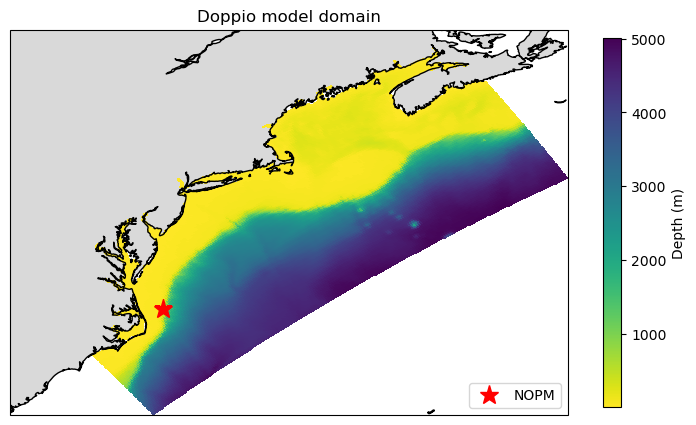

In [3]:
# Bathymetry (h) on the model grid; mask_rho is 1 over water and 0 over land
depth = ds1.h.where(ds1.mask_rho == 1)

fig, ax = plt.subplots(figsize=(9, 6), subplot_kw={"projection": ccrs.PlateCarree()})
pc = ax.pcolormesh(ds1.lon_rho, ds1.lat_rho, depth, cmap="viridis_r", transform=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="0.85")
ax.coastlines()
ax.plot(nopm_lon, nopm_lat, "r*", ms=14, transform=ccrs.PlateCarree(), label="NOPM")
ax.legend(loc="lower right")
fig.colorbar(pc, label="Depth (m)", shrink=0.8)
ax.set_title("Doppio model domain")
plt.show()

In [4]:
# Nearest model grid cell to NOPM (the grid is the same in every file)
dist = (ds1.lat_rho - nopm_lat) ** 2 + ((ds1.lon_rho - nopm_lon) * np.cos(np.deg2rad(nopm_lat))) ** 2
j, i = np.unravel_index(np.argmin(dist.values), dist.shape)
print(f"Nearest cell: eta_rho={j}, xi_rho={i}, depth={float(ds1.h[j, i]):.0f} m")

Nearest cell: eta_rho=45, xi_rho=44, depth=246 m


## 2. Three ways to extract a time series

The task is the same each time: surface temperature (`s_rho=-1`) at the NOPM grid cell for November 2024. Each strategy stores its result in `series` and its timing in `timings`, and they are compared in section 3.

The files covering November 2024 can be worked out from their numbers, without listing the bucket.

In [5]:
def avg_file_numbers(start, end):
    """Numbers of the avg files covering [start, end] (dates as 'YYYY-MM-DD')."""
    first_day = np.datetime64("2007-01-02")
    first = (np.datetime64(start) - first_day).astype(int) // 3 * 3 + 366
    last = (np.datetime64(end) - first_day).astype(int) // 3 * 3 + 366
    return list(range(int(first), int(last) + 1, 3))

nums = avg_file_numbers("2024-11-01", "2024-11-30")
print(f"{len(nums)} files: {nums[0]} ... {nums[-1]}")

timings, series = {}, {}

10 files: 6879 ... 6906


### A. NetCDF, one file at a time

Open each file, pull out the point, then join the pieces. Opening and reading are interleaved, so they are timed together.

In [6]:
label = "NetCDF, one file at a time"
t0 = time.time()
parts = []
for n in nums:
    with xr.open_dataset(open_avg(n), engine="h5netcdf") as d:
        parts.append(d.temp.isel(s_rho=-1, eta_rho=j, xi_rho=i).load())
series[label] = xr.concat(parts, dim="ocean_time")
timings[label] = {"open_s": np.nan, "read_s": time.time() - t0}
print(f"{label}: {timings[label]['read_s']:.1f}s")

NetCDF, one file at a time: 11.4s


### B. NetCDF files combined with `open_mfdataset`

Open all the files as one dataset. Since the grid is the same in every file, `coords="minimal"` and `compat="override"` avoid comparing it across files. Nothing is read until `.load()`.

In [7]:
label = "NetCDF, open_mfdataset"
t0 = time.time()
ds_nc = xr.open_mfdataset(
    [open_avg(n) for n in nums], engine="h5netcdf", combine="by_coords",
    data_vars="minimal", coords="minimal", compat="override",
)
t1 = time.time()
series[label] = ds_nc.temp.isel(s_rho=-1, eta_rho=j, xi_rho=i).load()
timings[label] = {"open_s": t1 - t0, "read_s": time.time() - t1}
print(f"{label}: open {timings[label]['open_s']:.1f}s, read {timings[label]['read_s']:.1f}s")

NetCDF, open_mfdataset: open 10.1s, read 5.0s


### C. The Zarr reference file

`xr.open_zarr(url)` fails on this file with `GroupNotFoundError`, because it is a reference file and not a Zarr folder. Instead we open it through fsspec's `reference` filesystem (the `asynchronous` settings are needed with Zarr 3). The one-time open downloads the 42 MB index. After that we select by time and never need to know which file holds what.

In [8]:
label = "Zarr reference"
zarr_url = f"https://{BUCKET}.s3.amazonaws.com/avg/doppio_avg.zarr"

t0 = time.time()
fs = fsspec.filesystem(
    "reference",
    fo=zarr_url,
    remote_protocol="s3",
    remote_options={"anon": True, "asynchronous": True},
    asynchronous=True,
)
ds_zarr = xr.open_dataset(FsspecStore(fs, read_only=True), engine="zarr", consolidated=False, chunks={})
t1 = time.time()
series[label] = (
    ds_zarr.temp.sel(ocean_time=slice("2024-11-01", "2024-11-30"))
    .isel(s_rho=-1, eta_rho=j, xi_rho=i)
    .load()
)
timings[label] = {"open_s": t1 - t0, "read_s": time.time() - t1}
print(f"{label}: open {timings[label]['open_s']:.1f}s, read {timings[label]['read_s']:.1f}s")
ds_zarr

Zarr reference: open 5.1s, read 0.4s


<xarray.Dataset> Size: 141GB
Dimensions:         (tracer: 2, s_rho: 40, s_w: 41, boundary: 4, eta_rho: 106,
                     xi_rho: 242, eta_psi: 105, xi_psi: 241, eta_u: 106,
                     xi_u: 241, eta_v: 105, xi_v: 242, ocean_time: 6573)
Coordinates:
  * s_rho           (s_rho) float64 320B -0.9875 -0.9625 ... -0.0375 -0.0125
  * s_w             (s_w) float64 328B -1.0 -0.975 -0.95 ... -0.05 -0.025 nan
    lat_rho         (eta_rho, xi_rho) float64 205kB dask.array<chunksize=(106, 242), meta=np.ndarray>
    lon_rho         (eta_rho, xi_rho) float64 205kB dask.array<chunksize=(106, 242), meta=np.ndarray>
    lat_psi         (eta_psi, xi_psi) float64 202kB dask.array<chunksize=(105, 241), meta=np.ndarray>
    lon_psi         (eta_psi, xi_psi) float64 202kB dask.array<chunksize=(105, 241), meta=np.ndarray>
    lat_u           (eta_u, xi_u) float64 204kB dask.array<chunksize=(106, 241), meta=np.ndarray>
    lon_u           (eta_u, xi_u) float64 204kB dask.array<chunksize=(106, 241), meta=np.ndarray>
    lat_v           (eta_v, xi_v) float64 203kB dask.array<chunksize=(105, 242), meta=np.ndarray>
    lon_v           (eta_v, xi_v) float64 203kB dask.array<chunksize=(105, 242), meta=np.ndarray>
  * ocean_time      (ocean_time) datetime64[ns] 53kB 2007-01-02T12:00:00 ... ...
Dimensions without coordinates: tracer, boundary, eta_rho, xi_rho, eta_psi,
                                xi_psi, eta_u, xi_u, eta_v, xi_v
Data variables: (12/97)
    Akk_bak         float64 8B ...
    Akp_bak         float64 8B ...
    Akt_bak         (tracer) float64 16B dask.array<chunksize=(2,), meta=np.ndarray>
    Akv_bak         float64 8B ...
    Charnok_alpha   float64 8B ...
    CrgBan_cw       float64 8B ...
    ...              ...
    ubar            (ocean_time, eta_u, xi_u) float32 672MB dask.array<chunksize=(3, 106, 241), meta=np.ndarray>
    v               (ocean_time, s_rho, eta_v, xi_v) float32 27GB dask.array<chunksize=(3, 1, 105, 242), meta=np.ndarray>
    vbar            (ocean_time, eta_v, xi_v) float32 668MB dask.array<chunksize=(3, 105, 242), meta=np.ndarray>
    w               (ocean_time, s_w, eta_rho, xi_rho) float32 28GB dask.array<chunksize=(3, 1, 106, 242), meta=np.ndarray>
    xl              float64 8B ...
    zeta            (ocean_time, eta_rho, xi_rho) float32 674MB dask.array<chunksize=(3, 106, 242), meta=np.ndarray>
Attributes: (12/32)
    CPP_options:       DOPPIO, ADD_FSOBC, ADD_M2OBC, ANA_BSFLUX, ANA_BTFLUX, ...
    Conventions:       CF-1.4, SGRID-0.3
    NCO:               netCDF Operators version 5.1.5 (Homepage = http://nco....
    NLM_LBC:           \nEDGE:  WEST   SOUTH  EAST   NORTH  \nzeta:  Cha    C...
    NLM_TADV:          \nADVECTION:   HORIZONTAL   VERTICAL     \ntemp:      ...
    ana_file:          ROMS/Functionals/ana_btflux.h
    ...                ...
    svn_url:           
    tide_file:         /home/om/roms/doppio/7km/doppio_tide_7km.nc
    tiling:            006x004
    title:             DOPPIO RBL4DVAR Data Assimilation
    type:              ROMS/TOMS nonlinear model averages file
    var_info:          ../Data/varinfo1040t_daily.dat

## 3. Summary

`open_s` is the time to open the data before reading (blank where opening and reading are interleaved) and `read_s` is the time to fetch the values.

In [9]:
timing = pd.DataFrame.from_dict(timings, orient="index")
timing["total_s"] = timing["open_s"].fillna(0) + timing["read_s"]
reference = series["NetCDF, open_mfdataset"].values
timing["identical_values"] = [np.array_equal(series[k].values, reference) for k in timing.index]
timing.round(1)

,open_s,read_s,total_s,identical_values
"NetCDF, one file at a time",NaN,11.4,11.4,True
"NetCDF, open_mfdataset",10.1,5.0,15.2,True
Zarr reference,5.1,0.4,5.5,True


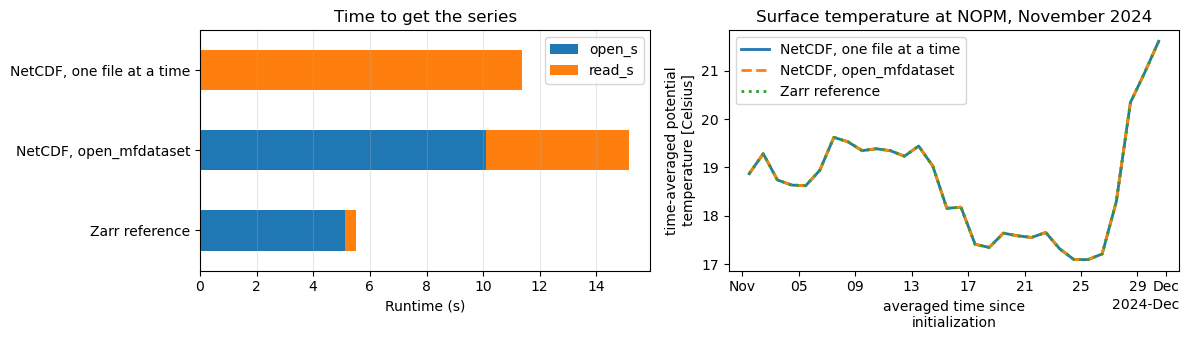

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

timing[["open_s", "read_s"]].fillna(0).plot.barh(stacked=True, ax=axes[0])
axes[0].invert_yaxis()
axes[0].set_xlabel("Runtime (s)")
axes[0].set_title("Time to get the series")
axes[0].grid(axis="x", alpha=0.3)

styles = {"NetCDF, one file at a time": "-", "NetCDF, open_mfdataset": "--", "Zarr reference": ":"}
for name, s in series.items():
    s.plot(ax=axes[1], ls=styles[name], lw=2, label=name)
axes[1].set_title("Surface temperature at NOPM, November 2024")
axes[1].legend()
plt.tight_layout()
plt.show()

### What to take away

- All three strategies return the same values. They differ in how much work it takes to get there.
- Every approach reads lazily: only the chunks you ask for are fetched from S3, never whole files.
- The NetCDF strategies pay a small cost to open each file, and you must work out which files cover your dates. That cost grows with the number of files.
- The Zarr reference file uses the same chunks as the NetCDF files, so it adds no data and no faster reads. It saves you from opening and combining many files, at the price of a one-time download of the index. Its advantage grows with the number of files involved: see `doppio_aws_benchmarks.ipynb`.
- ROMS uses a terrain-following vertical coordinate: `s_rho=-1` is the surface, not a fixed depth. Getting values at a given depth needs a conversion (`xroms` can do it).
- This AWS archive is a completed reanalysis for 2007-2024, so it holds nothing more recent. For later dates use another source (see `eccofs_access_and_datasets.ipynb`).